<a href="https://colab.research.google.com/github/misbakhulfajar27-killertheriper/Tugas_3/blob/main/Tugas3b_MISBAKHUL_FAJAR_047996694.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load dataset

In [2]:
# Baca file CSV (dipisahkan TAB, jadi sep="\t")
df = pd.read_csv("/content/cpa.csv", sep="\t")

# Cek ukuran data: (jumlah baris, jumlah kolom)
print("Ukuran data:", df.shape)

# Tampilkan 5 baris pertama
df.head()

Ukuran data: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


#Step2: lakukan Eksplorasi awal

In [3]:
# ===== STEP 2: EKSPLORASI AWAL =====

# 2.1 Struktur data: tipe data dan jumlah nilai terisi per kolom
df.info()

# 2.2 Missing value: tampilkan hanya kolom yang punya nilai kosong
missing = df.isnull().sum()
print("\nMissing value:\n", missing[missing > 0])

# 2.3 Cek baris duplikat
print("\nBaris duplikat:", df.duplicated().sum())

# 2.4 Frekuensi kategori pada kolom teks
print("\n", df["Education"].value_counts())
print("\n", df["Marital_Status"].value_counts())

# 2.5 Ringkasan statistik kolom numerik (lihat min dan max)
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


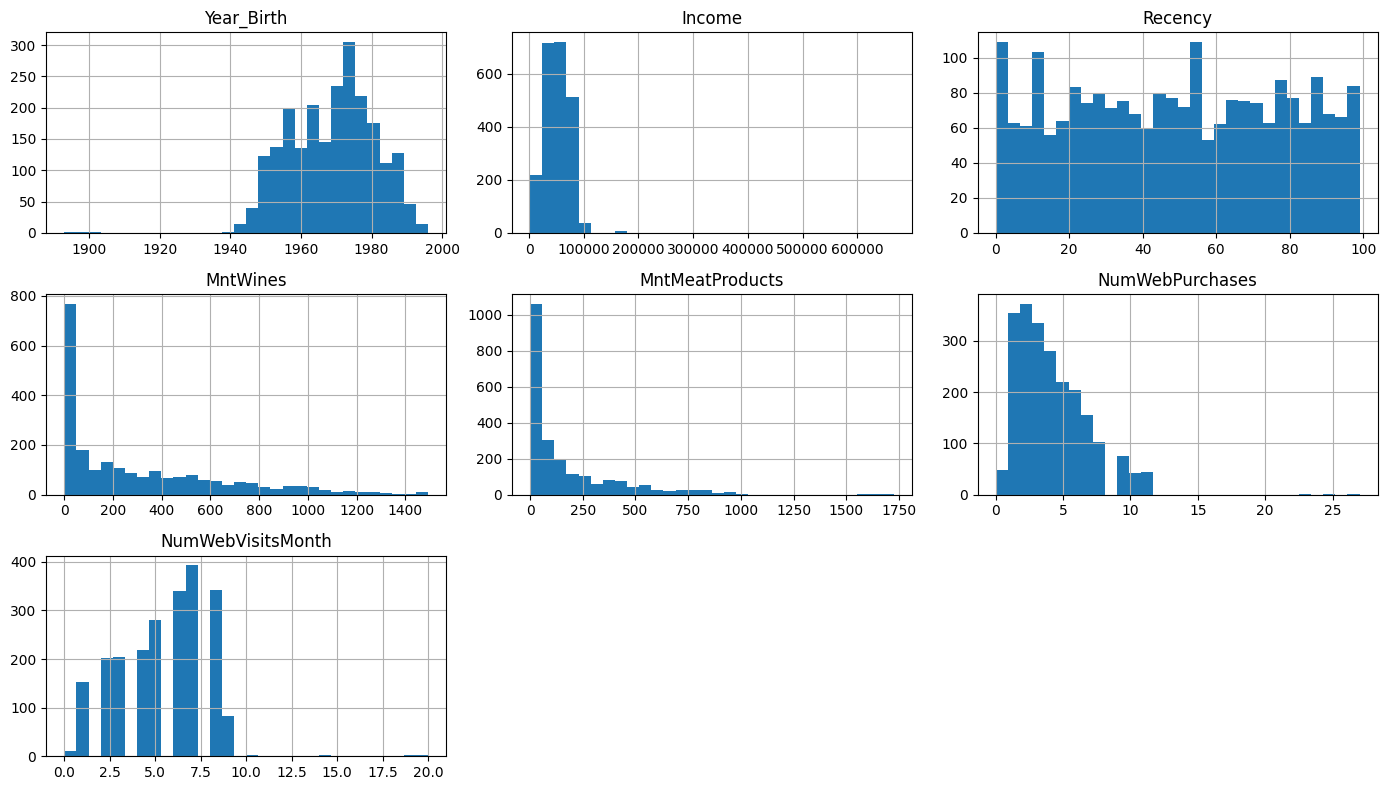

In [4]:
# 2.6 Distribusi fitur utama (histogram)
cols = ["Year_Birth", "Income", "Recency", "MntWines",
        "MntMeatProducts", "NumWebPurchases", "NumWebVisitsMonth"]
df[cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

# Step 3: Identifikasi kolom numerik & kategori

In [5]:
# ===== STEP 3: IDENTIFIKASI KOLOM NUMERIK & KATEGORI =====

# 3.1 Buang kolom yang tidak dipakai untuk klastering
#     ID = hanya penanda, Z_CostContact & Z_Revenue = nilainya konstan,
#     Dt_Customer = teks tanggal (dibuang agar sederhana)
drop_cols = ["ID", "Z_CostContact", "Z_Revenue", "Dt_Customer"]
df_model = df.drop(columns=drop_cols)

# 3.2 Pisahkan kolom numerik dan kategori berdasarkan tipe data
num_cols = df_model.select_dtypes(include="number").columns.tolist()
cat_cols = df_model.select_dtypes(exclude="number").columns.tolist()

# 3.3 Tampilkan hasilnya
print("Numerik  :", len(num_cols), num_cols)
print("Kategori :", len(cat_cols), cat_cols)

Numerik  : 23 ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response']
Kategori : 2 ['Education', 'Marital_Status']


# Step 4: Imputasi missing value

In [6]:
# ===== STEP 4: IMPUTASI MISSING VALUE =====

# 4.1 Salin data agar df_model asli tetap aman
df_imp = df_model.copy()

# 4.2 Numerik: isi dengan MEDIAN (tidak terpengaruh outlier seperti Income 666.666)
imp_num = SimpleImputer(strategy="median")
df_imp[num_cols] = imp_num.fit_transform(df_imp[num_cols])

# 4.3 Kategori: isi dengan MODUS / nilai paling sering muncul
imp_cat = SimpleImputer(strategy="most_frequent")
df_imp[cat_cols] = imp_cat.fit_transform(df_imp[cat_cols])

# 4.4 Cek hasil: total missing harus 0, dan median Income yang dipakai
print("Sisa missing:", df_imp.isnull().sum().sum())
print("Median Income:", imp_num.statistics_[num_cols.index("Income")])

Sisa missing: 0
Median Income: 51381.5


In [7]:
# ===== STEP 4b: BERSIHKAN OUTLIER & KATEGORI JANGGAL =====

# 4b.1 mengitung dulu berapa baris yang bermasalah
print("Year_Birth < 1920 :", (df_imp["Year_Birth"] < 1920).sum())
print("Income > 200000   :", (df_imp["Income"] > 200000).sum())

# 4b.2 Buang baris outlier (tahun lahir tidak wajar & Income ekstrem)
df_imp = df_imp[(df_imp["Year_Birth"] >= 1920) & (df_imp["Income"] <= 200000)]
df_imp = df_imp.reset_index(drop=True)

# 4b.3 Gabungkan kategori janggal Marital_Status ke "Single"
df_imp["Marital_Status"] = df_imp["Marital_Status"].replace(
    {"Alone": "Single", "Absurd": "Single", "YOLO": "Single"}
)

# 4b.4 Cek hasil
print("\nUkuran data sekarang:", df_imp.shape)
print(df_imp["Marital_Status"].value_counts())

Year_Birth < 1920 : 3
Income > 200000   : 1

Ukuran data sekarang: (2236, 25)
Marital_Status
Married     864
Together    578
Single      486
Divorced    231
Widow        77
Name: count, dtype: int64



# Step 5: Encoding fitur kategori

In [8]:
# ===== STEP 5: ENCODING FITUR KATEGORI =====

# 5.1 One-Hot Encoding: tiap kategori jadi kolom 0/1
#     (K-Means tidak bisa memakai teks, jadi harus diubah ke angka)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df_imp[cat_cols])

# 5.2 Ubah hasilnya jadi DataFrame dengan nama kolom yang jelas
encoded_cols = ohe.get_feature_names_out(cat_cols)
df_encoded = pd.DataFrame(encoded, columns=encoded_cols, index=df_imp.index)

# 5.3 Cek hasil
print("Ukuran hasil encoding:", df_encoded.shape)
print(list(encoded_cols))
df_encoded.head()

Ukuran hasil encoding: (2236, 10)
['Education_2n Cycle', 'Education_Basic', 'Education_Graduation', 'Education_Master', 'Education_PhD', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow']


,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


#Gabungkan data numerik & hasil encoding

In [9]:
# ===== GABUNGKAN DATA NUMERIK & HASIL ENCODING =====

# 1. Gabungkan kolom numerik (23) dengan kolom hasil One-Hot (10) ke samping
X = pd.concat([df_imp[num_cols], df_encoded], axis=1)

# 2. Cek hasil: harus 23 + 10 = 33 kolom, dan tidak ada missing value
print("Ukuran data gabungan:", X.shape)
print("Sisa missing:", X.isnull().sum().sum())
X.head()

Ukuran data gabungan: (2236, 33)
Sisa missing: 0


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,1957.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1954.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1965.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1984.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1981.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


# Step 6: Scaling data

In [10]:
# ===== STEP 6: SCALING DATA =====

# 6.1 Standardisasi: tiap kolom diubah jadi rata-rata 0 dan std 1
#     (K-Means memakai jarak, jadi Income yang angkanya puluhan ribu
#      akan mendominasi Kidhome yang hanya 0-2 bila tidak di-scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6.2 Ubah ke DataFrame agar nama kolom tetap terbaca
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# 6.3 Cek hasil: rata-rata mendekati 0 dan std mendekati 1
print("Ukuran data:", X_scaled_df.shape)
print("Rata-rata terbesar (nilai mutlak):", round(abs(X_scaled_df.mean()).max(), 4))
print("Std terkecil & terbesar:", round(X_scaled_df.std().min(), 2), round(X_scaled_df.std().max(), 2))

Ukuran data: (2236, 33)
Rata-rata terbesar (nilai mutlak): 0.0
Std terkecil & terbesar: 1.0 1.0



# Step 7: Tentukan jumlah cluster optimal (Elbow + Silhouette)

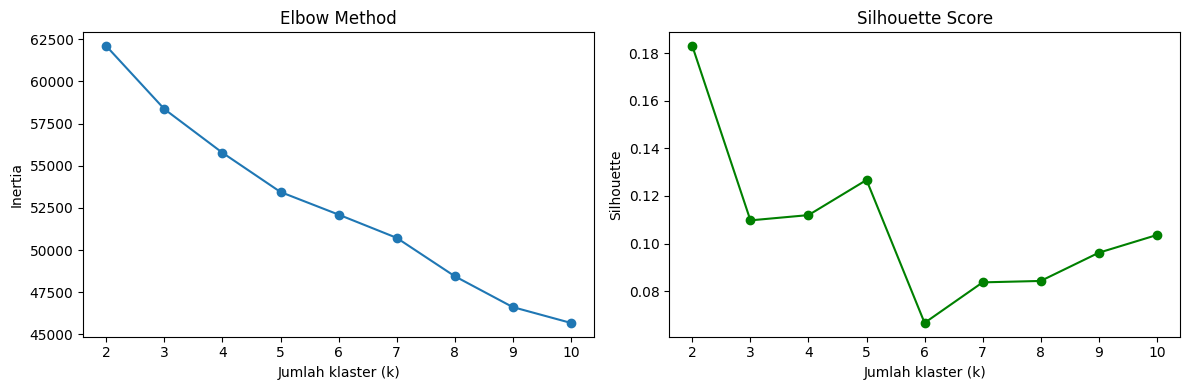

k = 2 -> silhouette = 0.1829
k = 3 -> silhouette = 0.1097
k = 4 -> silhouette = 0.1120
k = 5 -> silhouette = 0.1267
k = 6 -> silhouette = 0.0667
k = 7 -> silhouette = 0.0837
k = 8 -> silhouette = 0.0843
k = 9 -> silhouette = 0.0961
k = 10 -> silhouette = 0.1036


In [11]:
# ===== STEP 7: ELBOW + SILHOUETTE =====

# 7.1 Coba k = 2 sampai 10, simpan inertia dan silhouette tiap k
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)                       # untuk Elbow
    sil_scores.append(silhouette_score(X_scaled, labels))  # untuk Silhouette

# 7.2 Gambar kedua grafik berdampingan
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_range, inertias, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Jumlah klaster (k)")
ax[0].set_ylabel("Inertia")

ax[1].plot(k_range, sil_scores, marker="o", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Jumlah klaster (k)")
ax[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

# 7.3 Tampilkan nilai silhouette tiap k
for k, s in zip(k_range, sil_scores):
    print(f"k = {k} -> silhouette = {s:.4f}")

# Step 8: Pilih k optimal dan klasterisasi

In [12]:
# ===== STEP 8: PILIH K OPTIMAL & KLASTERISASI =====

# 8.1 Pilih jumlah klaster (dari Elbow + Silhouette di Step 7)
k_optimal = 2

# 8.2 Jalankan K-Means dengan k pilihan
kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)

# 8.3 Simpan label klaster ke data (untuk profiling di Step 10)
df_clustered = df_imp.copy()
df_clustered["Cluster"] = labels

# 8.4 Cek jumlah pelanggan per klaster
print("Silhouette:", round(silhouette_score(X_scaled, labels), 4))
print(df_clustered["Cluster"].value_counts().sort_index())

Silhouette: 0.1829
Cluster
0    1355
1     881
Name: count, dtype: int64


# Step 9: Visualisasi klaster dengan PCA 2D

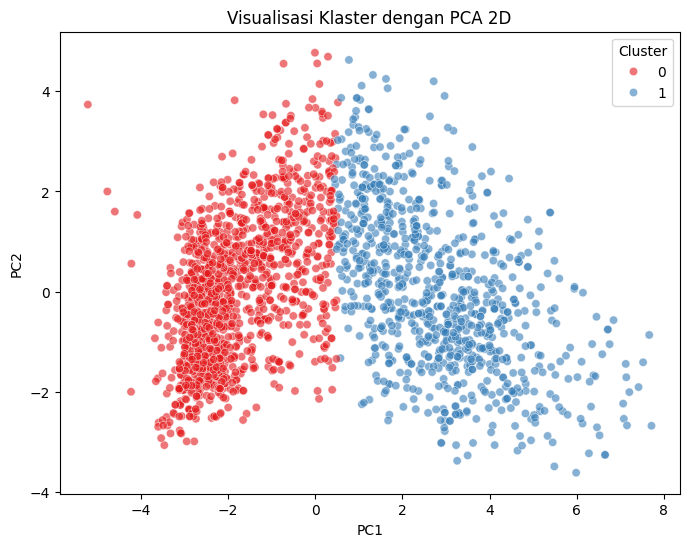

Varians dijelaskan: [0.204 0.067]
Total: 0.271


In [13]:
# ===== STEP 9: VISUALISASI KLASTER DENGAN PCA 2D =====

# 9.1 Ringkas 33 fitur menjadi 2 komponen utama (agar bisa digambar 2D)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 9.2 Simpan hasilnya ke DataFrame bersama label klaster
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df_pca["Cluster"] = labels

# 9.3 Gambar scatterplot, warna = klaster
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Cluster",
                palette="Set1", alpha=0.6)
plt.title("Visualisasi Klaster dengan PCA 2D")
plt.show()

# 9.4 Berapa persen informasi yang ditangkap 2 komponen ini
print("Varians dijelaskan:", pca.explained_variance_ratio_.round(3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

# Step 10: Profiling cluster (rata-rata fitur per cluster)

In [14]:
# ===== STEP 10: PROFILING KLASTER =====

# 10.1 Rata-rata tiap fitur numerik per klaster (skala asli, bukan scaling)
profil = df_clustered.groupby("Cluster")[num_cols].mean().round(2).T
profil

Cluster,0,1
Year_Birth,1970.05,1967.12
Income,39226.13,71526.27
Kidhome,0.69,0.06
Teenhome,0.56,0.43
Recency,48.82,49.58
MntWines,106.17,608.60
MntFruits,6.79,56.25
MntMeatProducts,38.06,365.26
MntFishProducts,9.94,79.97
MntSweetProducts,6.88,58.15


In [15]:
# 10.2 Proporsi kategori per klaster (tiap baris dijumlah = 1)
print(pd.crosstab(df_clustered["Cluster"], df_clustered["Education"], normalize="index").round(2))
print()
print(pd.crosstab(df_clustered["Cluster"], df_clustered["Marital_Status"], normalize="index").round(2))

Education  2n Cycle  Basic  Graduation  Master   PhD
Cluster                                             
0              0.09   0.04        0.48    0.18  0.21
1              0.08   0.00        0.53    0.15  0.23

Marital_Status  Divorced  Married  Single  Together  Widow
Cluster                                                   
0                   0.10     0.40    0.22      0.26   0.03
1                   0.11     0.37    0.22      0.26   0.05



# Simpulkan Analisa dari hasil

**A. Profil Klaster (k = 2)**

- **Klaster 0 – "Pelanggan Hemat" (1.355 pelanggan):** Income rendah-menengah (±39.226), belanja kecil (wine ±106), banyak anak kecil (Kidhome 0,69), sering mengunjungi web (6,39 kali/bulan) tetapi jarang membeli, respons kampanye lebih rendah (9%).
- **Klaster 1 – "Pelanggan Premium" (881 pelanggan):** Income tinggi (±71.526), belanja besar (wine ±609), anak kecil sedikit (Kidhome 0,06), aktif membeli di toko, katalog, dan web, respons kampanye lebih tinggi (23%).
- **Tidak membedakan klaster:** Education, Marital_Status, Year_Birth, Recency, dan Complain hampir sama di kedua klaster.

**B. Kesimpulan**

1. **Preprocessing:** Missing value hanya di Income (24 baris), diimputasi dengan median. Empat baris outlier dibuang (tiga Year_Birth < 1920 dan satu Income 666.666). Kategori Marital_Status yang janggal digabung ke Single. Kolom kategori di-One-Hot Encoding, lalu semua fitur distandardisasi. Hasil akhir: 2.236 baris dan 33 fitur.
2. **Jumlah klaster:** Elbow tidak menunjukkan siku yang tegas, sedangkan Silhouette tertinggi di k = 2 (0,1829), sehingga dipilih k = 2. Silhouette di k = 5 (0,1267) juga cukup baik, tetapi nilainya lebih rendah dari k = 2, sehingga k = 2 dipilih sebagai yang paling kuat secara metrik.
3. **Segmentasi:** Pelanggan terbagi menjadi Pelanggan Hemat dan Pelanggan Premium. Pembedanya terutama pendapatan, jumlah belanja, kanal pembelian, dan kepemilikan anak kecil.
4. **Saran bisnis:** Premium cocok untuk produk berkualitas tinggi dan program loyalitas. Hemat cocok untuk diskon atau paket hemat, serta perbaikan konversi dari kunjungan web ke pembelian.
5. **Keterbatasan:** Silhouette rendah (0,18) dan PCA 2D hanya menjelaskan 27,1% varians, jadi batas antar klaster tidak tegas. Segmen ini lebih tepat dibaca sebagai spektrum daya beli.